# 04 — Cross-Modal Domain Adaptation & Few-Shot Fine-Tuning

**PI-CDA: Cross-Modal Digital Twin Adaptation for Industrial Action Recognition & Anticipation**

This notebook executes **Phase 2 & Phase 3** of the research plan:
1. **Unsupervised Domain Adaptation (UDA) Baselines (E3)**: Implement and benchmark DANN, DeepCORAL, and MMD.
2. **PI-CDA Framework (E4)**: Train with **CSTA (Contrastive Skeleton Topology Alignment)** combining instance NT-Xent, velocity MMD, and topology consistency, coupled with the **Action Precedence Automaton (APA)** inference filter.
3. **Few-Shot Adaptation (E5)**: Evaluate target transfer efficiency with $k \in \{1, 5, 10\}$ real samples per class.
4. **Ablation Study (E6)**: Quantify the exact contribution of each CSTA component and APA filtering.
5. **Checkpoint & Results Export**: Save adapted models and benchmark tables to `output/checkpoints/` and `output/results/`.


## 0. Setup, Reproducibility & Device Initialization


In [11]:
import os
import sys
import time
import math
import random
import json
import copy
from pathlib import Path
from typing import Dict, List, Tuple, Optional

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.autograd import Function

# Seeds
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {DEVICE}")

BASE_DIR = Path("/home/g0amer/Desktop/thesis/04_Cross_Modal_Digital_Twin")
DATA_DIR = BASE_DIR / "data"
CKPT_DIR = BASE_DIR / "output" / "checkpoints"
RESULTS_DIR = BASE_DIR / "output" / "results"
FIGURES_DIR = BASE_DIR / "output" / "figures"

for p in [CKPT_DIR, RESULTS_DIR, FIGURES_DIR]:
    p.mkdir(parents=True, exist_ok=True)


Using compute device: cuda


## 1. Action Definitions & Adjacency


In [12]:
ACTION_CLASSES = [
    "Picking up a part", "Positioning a part", "Aligning a part",
    "Fastening with screwdriver", "Hammering", "Inspecting a part",
    "Turning a part", "Placing a part aside", "Putting a part in bin",
    "Idle / Waiting", "Adjusting workstation", "Cleaning surface",
    "Discarding defective part"
]
NUM_CLASSES = len(ACTION_CLASSES)

SHORT_LABELS = [
    "Pick", "Position", "Align", "Screw", "Hammer",
    "Inspect", "Turn", "Aside", "Bin", "Idle",
    "Adjust", "Clean", "Discard"
]

SKELETON_EDGES = [
    (0, 1), (1, 2), (2, 3), (3, 4),
    (2, 5), (5, 6), (6, 7),
    (2, 8), (8, 9), (9, 10),
    (0, 11), (11, 12), (12, 13),
    (0, 14), (14, 15), (15, 16)
]
NUM_JOINTS = 17

def get_adjacency_matrix(num_joints: int = 17, edges: list = SKELETON_EDGES) -> torch.Tensor:
    adj = torch.zeros(num_joints, num_joints)
    for i in range(num_joints):
        adj[i, i] = 1.0
    for i, j in edges:
        adj[i, j] = 1.0
        adj[j, i] = 1.0
    deg = adj.sum(dim=1)
    deg_inv_sqrt = torch.pow(deg, -0.5)
    deg_inv_sqrt[torch.isinf(deg_inv_sqrt)] = 0.0
    norm_adj = deg_inv_sqrt.view(-1, 1) * adj * deg_inv_sqrt.view(1, -1)
    return norm_adj

NORM_ADJ = get_adjacency_matrix(NUM_JOINTS, SKELETON_EDGES).to(DEVICE)


## 2. CTR-GCN Architecture


In [13]:
# ============================================================================
# Unified Model Architecture — CTR-GCN (with channel-wise topology corr maps)
#   Upgraded with Multi-Scale Temporal Convolutions (MS-TCN) to capture both
#   rapid manipulation motions and extended posture transitions (Phase A2).
#   This definition is IDENTICAL to NB03 & NB05 for strict checkpoint compatibility.
# ============================================================================

class TemporalConv(nn.Module):
    """
    Multi-Scale Temporal Convolution (MS-TCN)
    Captures fast manipulation actions (short kernel) as well as slower body transitions (long kernel).
    Branch 1: kernel (5, 1) - fast transient manipulation motions
    Branch 2: kernel (9, 1) - standard action tempo
    Branch 3: kernel (13, 1) - extended posture transitions
    Branch 4: MaxPool + 1x1 conv - temporal max pooling features
    """
    def __init__(self, in_channels: int, out_channels: int, stride: int = 1, dropout: float = 0.1):
        super().__init__()
        mid_c = out_channels // 4
        self.branch1 = nn.Sequential(
            nn.Conv2d(in_channels, mid_c, kernel_size=1),
            nn.BatchNorm2d(mid_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(mid_c, mid_c, kernel_size=(5, 1), stride=(stride, 1), padding=(2, 0)),
            nn.BatchNorm2d(mid_c)
        )
        self.branch2 = nn.Sequential(
            nn.Conv2d(in_channels, mid_c, kernel_size=1),
            nn.BatchNorm2d(mid_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(mid_c, mid_c, kernel_size=(9, 1), stride=(stride, 1), padding=(4, 0)),
            nn.BatchNorm2d(mid_c)
        )
        self.branch3 = nn.Sequential(
            nn.Conv2d(in_channels, mid_c, kernel_size=1),
            nn.BatchNorm2d(mid_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(mid_c, mid_c, kernel_size=(13, 1), stride=(stride, 1), padding=(6, 0)),
            nn.BatchNorm2d(mid_c)
        )
        self.branch_pool = nn.Sequential(
            nn.MaxPool2d(kernel_size=(3, 1), stride=(stride, 1), padding=(1, 0)),
            nn.Conv2d(in_channels, out_channels - 3 * mid_c, kernel_size=1),
            nn.BatchNorm2d(out_channels - 3 * mid_c)
        )
        self.residual = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=(stride, 1)),
            nn.BatchNorm2d(out_channels)
        ) if (stride != 1 or in_channels != out_channels) else nn.Identity()
        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        res = self.residual(x)
        b1 = self.branch1(x)
        b2 = self.branch2(x)
        b3 = self.branch3(x)
        bp = self.branch_pool(x)
        out = torch.cat([b1, b2, b3, bp], dim=1)
        return self.dropout(self.relu(out + res))


class CTRGraphConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, base_adj: torch.Tensor, reduction: int = 8):
        super().__init__()
        self.num_joints = base_adj.size(0)
        self.register_buffer("base_adj", base_adj)
        self.alpha = nn.Parameter(torch.zeros(self.num_joints, self.num_joints))
        mid_channels = max(in_channels // reduction, 16)
        self.phi = nn.Conv2d(in_channels, mid_channels, kernel_size=1)
        self.psi = nn.Conv2d(in_channels, mid_channels, kernel_size=1)
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=1)
        self.bn   = nn.BatchNorm2d(out_channels)

    def forward(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        B, C, T, V = x.shape
        base    = self.base_adj + self.alpha
        x_mean  = x.mean(dim=2, keepdim=True)
        phi_x   = self.phi(x_mean)
        psi_x   = self.psi(x_mean)
        corr    = torch.matmul(phi_x.squeeze(2).permute(0, 2, 1), psi_x.squeeze(2))
        corr    = torch.tanh(corr / math.sqrt(phi_x.size(1)))
        x_proj  = self.conv(x)
        out     = torch.einsum("bctv,vw->bctw", x_proj, base) + torch.einsum("bctv,bvw->bctw", x_proj, corr)
        return self.bn(out), corr


class CTRGCNBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, base_adj: torch.Tensor, stride: int = 1, dropout: float = 0.1):
        super().__init__()
        self.gcn = CTRGraphConv(in_channels, out_channels, base_adj)
        self.tcn = TemporalConv(out_channels, out_channels, stride=stride, dropout=dropout)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        gcn_out, corr = self.gcn(x)
        return self.tcn(self.relu(gcn_out)), corr


class CTRGCN(nn.Module):
    def __init__(self, in_channels: int = 3, num_classes: int = 13,
                 base_adj: torch.Tensor = None, base_dim: int = 64, dropout: float = 0.1):
        super().__init__()
        self.init_conv = nn.Sequential(
            nn.Conv2d(in_channels, base_dim, kernel_size=1),
            nn.BatchNorm2d(base_dim),
            nn.ReLU(inplace=True)
        )
        self.layer1 = CTRGCNBlock(base_dim,     base_dim,     base_adj, stride=1, dropout=dropout)
        self.layer2 = CTRGCNBlock(base_dim,     base_dim * 2, base_adj, stride=2, dropout=dropout)
        self.layer3 = CTRGCNBlock(base_dim * 2, base_dim * 4, base_adj, stride=2, dropout=dropout)
        self.feature_dim = base_dim * 4
        self.classifier  = nn.Linear(self.feature_dim, num_classes)

    def extract_features(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor, List[torch.Tensor]]:
        x = self.init_conv(x)
        x, c1 = self.layer1(x)
        x, c2 = self.layer2(x)
        x, c3 = self.layer3(x)
        global_feat = x.mean(dim=[2, 3])
        return global_feat, x, [c1, c2, c3]

    def forward(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        global_feat, _, _ = self.extract_features(x)
        return self.classifier(global_feat), global_feat

print("Unified MS-TCN CTR-GCN architecture defined ✓")



Unified MS-TCN CTR-GCN architecture defined ✓


## 3. Adaptation Modules: CSTA Loss, APA Constraint & Baselines
- **CSTA Loss**: NT-Xent + velocity distribution MMD + topology consistency.
- **Action Precedence Automaton (APA)**: Prior transition graph enforcing assembly sequence validity.
- **DANN Gradient Reversal Layer**: Minimax adversarial domain alignment.
- **DeepCORAL**: Covariance matrix distance minimization.


In [14]:
# ============================================================================
# Adaptation Modules: Fixed CSTA Loss, Data-Driven APA, UDA Baselines
# ============================================================================

# ── MMD (RBF kernel) ─────────────────────────────────────────────────────────
def rbf_kernel(x: torch.Tensor, y: torch.Tensor, sigmas=(1.0, 5.0, 10.0)) -> torch.Tensor:
    xx = torch.cdist(x, x).pow(2)
    yy = torch.cdist(y, y).pow(2)
    xy = torch.cdist(x, y).pow(2)
    k_xx = k_yy = k_xy = 0.0
    for s in sigmas:
        g = 1.0 / (2.0 * s * s)
        k_xx = k_xx + torch.exp(-g * xx)
        k_yy = k_yy + torch.exp(-g * yy)
        k_xy = k_xy + torch.exp(-g * xy)
    return k_xx.mean() + k_yy.mean() - 2.0 * k_xy.mean()


# ── DeepCORAL ────────────────────────────────────────────────────────────────
def coral_loss(source: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
    d = source.size(1)
    cs = (source - source.mean(0)).T @ (source - source.mean(0)) / (source.size(0) - 1)
    ct = (target - target.mean(0)).T @ (target - target.mean(0)) / (target.size(0) - 1)
    return (cs - ct).pow(2).sum() / (4.0 * d * d)


# ── Gradient Reversal (DANN) ──────────────────────────────────────────────────
class GradientReversalFn(Function):
    @staticmethod
    def forward(ctx, x, alpha):  ctx.alpha = alpha;  return x.clone()
    @staticmethod
    def backward(ctx, g):        return g.neg() * ctx.alpha, None

class GradientReversal(nn.Module):
    def __init__(self, alpha=1.0): super().__init__(); self.alpha = alpha
    def forward(self, x):  return GradientReversalFn.apply(x, self.alpha)

class DomainDiscriminator(nn.Module):
    def __init__(self, in_features=256, hidden_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden_dim), nn.BatchNorm1d(hidden_dim), nn.ReLU(True),
            nn.Linear(hidden_dim, hidden_dim // 2), nn.BatchNorm1d(hidden_dim // 2), nn.ReLU(True),
            nn.Linear(hidden_dim // 2, 2)
        )
    def forward(self, x): return self.net(x)


# ── FIXED PI-CDA (CSTA Loss) ──────────────────────────────────────────────────
# Phase B Improvements:
#   1. Feature-level MMD alongside Prototype Alignment (B2) - unifies global + class alignment
#   2. Soft pseudo-labels with confidence thresholding (B4) - eliminates noisy early pseudo-labels
#   3. Zeroed raw velocity MMD by default (B1) - prevents sensor noise mismatch from distorting features
#   4. Topology Consistency Loss (α regularization)
class CSTALoss(nn.Module):
    def __init__(self, num_classes: int = 13, feat_dim: int = 256,
                 temperature: float = 0.07, lambda_vel: float = 0.0,
                 lambda_topo: float = 0.5, lambda_proto: float = 1.0,
                 lambda_mmd: float = 1.5):
        super().__init__()
        self.num_classes   = num_classes
        self.feat_dim      = feat_dim
        self.temperature   = temperature
        self.lambda_vel    = lambda_vel
        self.lambda_topo   = lambda_topo
        self.lambda_proto  = lambda_proto
        self.lambda_mmd    = lambda_mmd
        # Exponential moving average prototypes (not learnable params)
        self.register_buffer("prototypes", torch.zeros(num_classes, feat_dim))
        self.register_buffer("proto_counts", torch.zeros(num_classes))

    @torch.no_grad()
    def update_prototypes(self, feats: torch.Tensor, labels: torch.Tensor, momentum: float = 0.9):
        for c in range(self.num_classes):
            mask = (labels == c)
            if mask.sum() == 0:
                continue
            class_mean = feats[mask].mean(0)
            if self.proto_counts[c] == 0:
                self.prototypes[c] = class_mean
            else:
                self.prototypes[c] = momentum * self.prototypes[c] + (1 - momentum) * class_mean
            self.proto_counts[c] += 1

    def prototype_alignment_loss(self, target_feats: torch.Tensor, threshold: float = 0.6) -> torch.Tensor:
        """
        Confidence-thresholded soft assignment loss (Phase B4).
        Only aligns target samples where assignment probability to nearest prototype exceeds threshold.
        """
        t_norm = F.normalize(target_feats, dim=-1)
        p_norm = F.normalize(self.prototypes, dim=-1)   # (K, D)
        sim    = torch.matmul(t_norm, p_norm.T) / self.temperature  # (B, K)
        probs  = F.softmax(sim, dim=-1)
        max_prob, pseudo = probs.max(dim=1)
        
        mask = max_prob >= threshold
        if mask.sum() > 0:
            loss_proto = F.cross_entropy(sim[mask], pseudo[mask])
        else:
            # Fall back to mild entropy minimization across prototypes
            loss_proto = - (probs * F.log_softmax(sim, dim=-1)).sum(dim=-1).mean()
        return loss_proto

    def velocity_mmd_loss(self, src_x: torch.Tensor, tgt_x: torch.Tensor) -> torch.Tensor:
        v_s = (src_x[:, :, 1:, :] - src_x[:, :, :-1, :]).norm(dim=1)
        v_t = (tgt_x[:, :, 1:, :] - tgt_x[:, :, :-1, :]).norm(dim=1)
        vmag_s = v_s.mean(dim=1).reshape(-1, 1)
        vmag_t = v_t.mean(dim=1).reshape(-1, 1)
        return rbf_kernel(vmag_s, vmag_t)

    def topology_loss(self, corrs_s: List, corrs_t: List) -> torch.Tensor:
        loss = 0.0
        for cs, ct in zip(corrs_s, corrs_t):
            loss = loss + F.mse_loss(cs.mean(0), ct.mean(0))
        return loss / max(len(corrs_s), 1)

    def forward(self, src_feat, src_labels, tgt_feat, src_x=None, tgt_x=None,
                corrs_s=None, corrs_t=None, use_vel=False, use_topo=True, use_mmd=True,
                warmup_w=1.0):
        # Update source prototypes with labelled source features
        self.update_prototypes(src_feat.detach(), src_labels)

        # 1. Prototype-based target alignment (Phase B4)
        L_proto = self.prototype_alignment_loss(tgt_feat)

        # 2. Feature-level MMD (Phase B2)
        L_mmd = torch.tensor(0.0, device=src_feat.device)
        if use_mmd:
            L_mmd = rbf_kernel(src_feat, tgt_feat)

        # 3. Velocity MMD (Phase B1 - disabled by default)
        L_vel = torch.tensor(0.0, device=src_feat.device)
        if use_vel and src_x is not None and tgt_x is not None:
            L_vel = self.velocity_mmd_loss(src_x, tgt_x)

        # 4. Topology consistency
        L_topo = torch.tensor(0.0, device=src_feat.device)
        if use_topo and corrs_s and corrs_t:
            L_topo = self.topology_loss(corrs_s, corrs_t)

        total = warmup_w * (self.lambda_proto * L_proto
                            + self.lambda_mmd  * L_mmd
                            + self.lambda_vel  * L_vel
                            + self.lambda_topo * L_topo)
        return total, {"proto": L_proto.item(), "mmd": L_mmd.item(), "vel": L_vel.item(), "topo": L_topo.item()}


# ── Data-Driven APA (Additive Bayesian Log-Prior, Phase C1/C2) ────────────────
class ActionPrecedenceAutomaton:
    """
    Action Precedence Automaton whose transition matrix is LEARNED from data
    (saved by NB03). Uses additive log-prior to maintain calibration without
    zeroing out valid predictions.
    """
    def __init__(self, num_classes: int = 13, ckpt_dir: Path = None, eps_smooth: float = 0.25):
        self.num_classes = num_classes
        apa_path = (ckpt_dir / "apa_transition_matrix.npy") if ckpt_dir else None

        if apa_path and apa_path.exists():
            matrix = np.load(str(apa_path))
            print(f"  Loaded learned APA matrix from {apa_path} ✓")
        else:
            valid_pairs = [
                (0, 1), (1, 2), (2, 3), (2, 4), (3, 5), (4, 5),
                (5, 6), (6, 0), (0, 7), (5, 8), (9, 0), (10, 0), (11, 0), (5, 12)
            ]
            matrix = np.ones((num_classes, num_classes), dtype=np.float32) * 0.5
            for src, dst in valid_pairs:
                matrix[src, dst] += 2.5
            matrix /= matrix.sum(axis=1, keepdims=True)
            print("  APA: using empirical assembly graph prior")

        # Apply label smoothing to ensure strict non-zero bounds
        uniform = np.ones_like(matrix) / num_classes
        matrix = (1.0 - eps_smooth) * matrix + eps_smooth * uniform
        self.P = torch.tensor(matrix, dtype=torch.float32).to(DEVICE)

    def filter_logits(self, logits: torch.Tensor, prev_action: Optional[torch.Tensor] = None, alpha: float = 0.25) -> torch.Tensor:
        """Additive Bayesian log-prior: logits + alpha * log(P(next|prev))."""
        if prev_action is None:
            return logits
        B = logits.size(0)
        prev = prev_action[:B].to(logits.device)
        trans_prior = self.P[prev]
        log_prior = torch.log(trans_prior + 1e-7)
        return logits + alpha * log_prior


apa = ActionPrecedenceAutomaton(NUM_CLASSES, ckpt_dir=CKPT_DIR)
print("Adaptation loss modules and data-driven APA initialised ✓")



  Loaded learned APA matrix from /home/g0amer/Desktop/thesis/04_Cross_Modal_Digital_Twin/output/checkpoints/apa_transition_matrix.npy ✓
Adaptation loss modules and data-driven APA initialised ✓


## 4. Dataset Loading


In [15]:
class SkeletonDataset(Dataset):
    def __init__(self, samples: List[Tuple[np.ndarray, int, str]], max_frames: int = 64):
        self.samples = samples
        self.max_frames = max_frames

    def __len__(self):
        return len(self.samples)

    def _pad_or_crop(self, seq: np.ndarray) -> np.ndarray:
        T = seq.shape[0]
        if T >= self.max_frames:
            start = np.random.randint(0, T - self.max_frames + 1)
            return seq[start:start + self.max_frames]
        else:
            pad = np.zeros((self.max_frames - T, *seq.shape[1:]), dtype=seq.dtype)
            return np.concatenate([seq, pad], axis=0)

    def __getitem__(self, idx):
        pos, label, subject_id = self.samples[idx]
        pos = self._pad_or_crop(pos)
        x = torch.from_numpy(pos.transpose(2, 0, 1)).float()
        return x, label, subject_id

# Reuse identical generation logic
def generate_benchmark_data(num_samples_per_class: int = 40):
    dt_samples, real_samples = [], []
    for c in range(NUM_CLASSES):
        for s in range(num_samples_per_class):
            T = np.random.randint(55, 90)
            t_arr = np.linspace(0, 2 * np.pi, T)[:, None, None]
            freq = 0.5 + 0.2 * c
            base_motion = np.sin(freq * t_arr) * 0.35
            pos = np.zeros((T, NUM_JOINTS, 3), dtype=np.float32)
            for j in range(NUM_JOINTS):
                pos[:, j, 0] = base_motion[:, 0, 0] * (j % 3 - 1) * 0.5 + np.sin(0.1 * j)
                pos[:, j, 1] = np.cos(freq * t_arr)[:, 0, 0] * 0.4 + (j // 3) * 0.3
                pos[:, j, 2] = np.sin(freq * 0.5 * t_arr)[:, 0, 0] * 0.25
            dt_samples.append((pos, c, f"dt_user_{s%12+1}"))

            # Real with domain shift
            pos_real = pos.copy() * np.random.uniform(0.92, 1.08)
            pos_real += np.random.normal(0, 0.04, pos.shape).astype(np.float32)
            for f_idx in range(1, T):
                if np.random.rand() < 0.10:
                    pos_real[f_idx] = pos_real[f_idx - 1]
            real_samples.append((pos_real, c, f"real_worker_{s%16+1}"))
            
    random.shuffle(dt_samples)
    split = int(len(dt_samples) * 0.8)
    return dt_samples[:split], dt_samples[split:], real_samples

dt_train_data, dt_val_data, real_data = generate_benchmark_data()
BATCH_SIZE = 32

# Loaders
source_loader = DataLoader(SkeletonDataset(dt_train_data), batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
# Target loader is UNLABELED during unsupervised adaptation
target_loader = DataLoader(SkeletonDataset(real_data), batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
target_eval_loader = DataLoader(SkeletonDataset(real_data), batch_size=BATCH_SIZE, shuffle=False)


## 5. Experiment 3 (E3): Classical UDA Baselines
Train CTR-GCN using DANN (Domain Adversarial), DeepCORAL, and MMD feature alignment.


In [16]:
@torch.no_grad()
def evaluate_target(model, dataloader, device,
                    apa_filter: Optional[ActionPrecedenceAutomaton] = None):
    model.eval()
    all_preds, all_targets = [], []
    for x, y, _ in dataloader:
        x = x.to(device)
        logits, _ = model(x)
        preds = logits.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(y.numpy())
    all_preds   = np.array(all_preds)
    all_targets = np.array(all_targets)
    acc      = accuracy_score(all_targets, all_preds)
    macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)
    return acc, macro_f1, all_preds, all_targets


def train_uda_baseline(method: str = "dann", epochs: int = 20):
    model = CTRGCN(in_channels=3, num_classes=NUM_CLASSES, base_adj=NORM_ADJ).to(DEVICE)
    src_ckpt = CKPT_DIR / "ctr_gcn_source_only.pth"
    if src_ckpt.exists():
        model.load_state_dict(torch.load(src_ckpt, map_location=DEVICE))
        print(f"  Loaded source checkpoint for {method.upper()} ✓")
    else:
        print("  No source checkpoint found — training from scratch")

    opt  = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-4)
    disc = DomainDiscriminator(in_features=256).to(DEVICE) if method == "dann" else None
    disc_opt = torch.optim.AdamW(disc.parameters(), lr=2e-4) if disc else None
    grl  = GradientReversal(alpha=1.0)
    cls_criterion = nn.CrossEntropyLoss()
    dom_criterion = nn.CrossEntropyLoss()

    for epoch in range(1, epochs + 1):
        model.train()
        target_iter = iter(target_loader)
        # Gradually increase GRL alpha
        alpha = min(1.0, 2.0 * epoch / epochs - 1.0) if method == "dann" else 1.0
        if disc: grl.alpha = alpha

        for x_s, y_s, _ in source_loader:
            try:
                x_t, _, _ = next(target_iter)
            except StopIteration:
                target_iter = iter(target_loader)
                x_t, _, _ = next(target_iter)

            x_s, y_s, x_t = x_s.to(DEVICE), y_s.to(DEVICE), x_t.to(DEVICE)
            opt.zero_grad()

            logits_s, feat_s = model(x_s)
            _,         feat_t = model(x_t)
            loss_cls = cls_criterion(logits_s, y_s)

            if method == "dann" and disc is not None:
                disc_opt.zero_grad()
                feat_all   = torch.cat([grl(feat_s), grl(feat_t)])
                dom_labels = torch.cat([
                    torch.zeros(feat_s.size(0), dtype=torch.long),
                    torch.ones (feat_t.size(0), dtype=torch.long)
                ]).to(DEVICE)
                loss_adapt = dom_criterion(disc(feat_all), dom_labels)
            elif method == "coral":
                loss_adapt = coral_loss(feat_s, feat_t) * 10.0
            elif method == "mmd":
                loss_adapt = rbf_kernel(feat_s, feat_t) * 2.0
            else:
                loss_adapt = torch.zeros(1, device=DEVICE)

            (loss_cls + loss_adapt).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            opt.step()
            if disc_opt: disc_opt.step()

    acc, f1, _, _ = evaluate_target(model, target_eval_loader, DEVICE)
    return acc, f1

print("--- Experiment 3 (E3): Classical UDA Baselines ---")
dann_acc,  dann_f1  = train_uda_baseline("dann",  epochs=20)
print(f"DANN:      Acc={dann_acc*100:.2f}%  F1={dann_f1*100:.2f}%")
coral_acc, coral_f1 = train_uda_baseline("coral", epochs=20)
print(f"DeepCORAL: Acc={coral_acc*100:.2f}%  F1={coral_f1*100:.2f}%")
mmd_acc,   mmd_f1   = train_uda_baseline("mmd",   epochs=20)
print(f"MMD:       Acc={mmd_acc*100:.2f}%  F1={mmd_f1*100:.2f}%")



--- Experiment 3 (E3): Classical UDA Baselines ---
  Loaded source checkpoint for DANN ✓
DANN:      Acc=72.88%  F1=72.68%
  Loaded source checkpoint for CORAL ✓
DeepCORAL: Acc=77.88%  F1=78.00%
  Loaded source checkpoint for MMD ✓
MMD:       Acc=78.85%  F1=78.92%


## 6. Experiment 4 (E4): Proposed PI-CDA Framework
Unsupervised adaptation using **CSTA** (instance NT-Xent + velocity MMD + topology consistency) and **APA** precedence filtering.


In [17]:
def train_picda(epochs: int = 35, use_vel: bool = False, use_topo: bool = True, use_mmd: bool = True):
    model = CTRGCN(in_channels=3, num_classes=NUM_CLASSES, base_adj=NORM_ADJ).to(DEVICE)
    src_ckpt = CKPT_DIR / "ctr_gcn_source_only.pth"
    if src_ckpt.exists():
        model.load_state_dict(torch.load(src_ckpt, map_location=DEVICE))
        print("  Loaded source checkpoint ✓")

    optimizer      = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-4)
    scheduler      = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)
    csta_criterion = CSTALoss(NUM_CLASSES, feat_dim=256, temperature=0.07,
                              lambda_vel=1.0 if use_vel else 0.0,
                              lambda_topo=0.5 if use_topo else 0.0,
                              lambda_proto=1.0,
                              lambda_mmd=1.5 if use_mmd else 0.0).to(DEVICE)
    cls_criterion  = nn.CrossEntropyLoss()

    for epoch in range(1, epochs + 1):
        model.train()
        # Gradual CSTA warmup: ramp from 0 → 1 over first 25% of epochs (Phase B3)
        warmup_w = min(1.0, epoch / max(1, int(0.25 * epochs)))
        target_iter = iter(target_loader)

        for x_s, y_s, _ in source_loader:
            try:
                x_t, _, _ = next(target_iter)
            except StopIteration:
                target_iter = iter(target_loader)
                x_t, _, _ = next(target_iter)

            x_s, y_s, x_t = x_s.to(DEVICE), y_s.to(DEVICE), x_t.to(DEVICE)
            optimizer.zero_grad()

            # Forward passes — get features + correlation maps
            feat_s, _, corr_s = model.extract_features(x_s)
            feat_t, _, corr_t = model.extract_features(x_t)
            logits_s           = model.classifier(feat_s)

            loss_cls  = cls_criterion(logits_s, y_s)
            loss_csta, csta_log = csta_criterion(
                feat_s, y_s, feat_t, x_s, x_t, corr_s, corr_t,
                use_vel=use_vel, use_topo=use_topo, use_mmd=use_mmd, warmup_w=warmup_w
            )
            (loss_cls + loss_csta).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            optimizer.step()

        scheduler.step()
        if epoch % 5 == 0 or epoch == 1:
            print(f"  Ep {epoch:02d}/{epochs} | warmup={warmup_w:.2f} | "
                  f"proto={csta_log['proto']:.3f} mmd={csta_log['mmd']:.3f} topo={csta_log['topo']:.3f}")

    acc, f1, preds, targets = evaluate_target(model, target_eval_loader, DEVICE)
    return model, acc, f1, preds, targets


print("--- Experiment 4 (E4): Proposed PI-CDA (Feature-MMD + Prototype-CSTA + Topology) ---")
picda_model, picda_acc, picda_f1, picda_preds, picda_targets = train_picda(epochs=35, use_vel=False, use_topo=True, use_mmd=True)
torch.save(picda_model.state_dict(), CKPT_DIR / "pi_cda_adapted.pth")

print("=" * 60)
print(f"EXPERIMENT 4 (E4) — PI-CDA UNSUPERVISED (IMPROVED):")
print(f"  Top-1 Accuracy: {picda_acc * 100:.2f}%")
print(f"  Macro-F1 Score: {picda_f1 * 100:.2f}%")
print("=" * 60)



--- Experiment 4 (E4): Proposed PI-CDA (Feature-MMD + Prototype-CSTA + Topology) ---
  Loaded source checkpoint ✓
  Ep 01/35 | warmup=0.12 | proto=0.173 mmd=0.119 topo=0.002
  Ep 05/35 | warmup=0.62 | proto=0.187 mmd=0.196 topo=0.012
  Ep 10/35 | warmup=1.00 | proto=0.144 mmd=0.112 topo=0.000
  Ep 15/35 | warmup=1.00 | proto=0.110 mmd=0.156 topo=0.006
  Ep 20/35 | warmup=1.00 | proto=0.120 mmd=0.121 topo=0.002
  Ep 25/35 | warmup=1.00 | proto=0.090 mmd=0.163 topo=0.002
  Ep 30/35 | warmup=1.00 | proto=0.098 mmd=0.163 topo=0.004
  Ep 35/35 | warmup=1.00 | proto=0.103 mmd=0.135 topo=0.003
EXPERIMENT 4 (E4) — PI-CDA UNSUPERVISED (IMPROVED):
  Top-1 Accuracy: 80.77%
  Macro-F1 Score: 80.82%


## 7. Experiment 5 (E5): Few-Shot Target Domain Fine-Tuning
Practical industrial deployment scenario: A factory engineer annotates $k \in \{1, 5, 10\}$ real demonstration sequences per action class.
Fine-tune the adapted PI-CDA model with these few real samples.


In [18]:
def extract_k_shot_dataset(data_list: List, k: int) -> Tuple[List, List]:
    class_buckets = {c: [] for c in range(NUM_CLASSES)}
    for item in data_list:
        class_buckets[item[1]].append(item)
    
    k_shot_train = []
    remaining_eval = []
    for c in range(NUM_CLASSES):
        random.shuffle(class_buckets[c])
        k_shot_train.extend(class_buckets[c][:k])
        remaining_eval.extend(class_buckets[c][k:])
    return k_shot_train, remaining_eval

few_shot_results = {}
k_shots = [1, 5, 10]

for k in k_shots:
    k_train, k_eval = extract_k_shot_dataset(real_data, k)
    k_train_loader = DataLoader(SkeletonDataset(k_train), batch_size=min(len(k_train), 16), shuffle=True)
    k_eval_loader = DataLoader(SkeletonDataset(k_eval), batch_size=BATCH_SIZE, shuffle=False)
    
    # Initialize from PI-CDA adapted weights
    ft_model = copy.deepcopy(picda_model)
    ft_optimizer = torch.optim.AdamW(ft_model.parameters(), lr=1e-4, weight_decay=1e-4)
    cls_criterion = nn.CrossEntropyLoss()
    
    ft_model.train()
    for epoch in range(10):
        for x, y, _ in k_train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            ft_optimizer.zero_grad()
            logits, _ = ft_model(x)
            loss = cls_criterion(logits, y)
            loss.backward()
            ft_optimizer.step()
            
    acc_k, f1_k, _, _ = evaluate_target(ft_model, k_eval_loader, DEVICE, apa_filter=apa)
    few_shot_results[k] = {"accuracy": float(acc_k), "macro_f1": float(f1_k)}
    print(f"PI-CDA + {k:02d}-shot Real Fine-Tuning: Acc = {acc_k*100:.2f}% | Macro-F1 = {f1_k*100:.2f}%")


PI-CDA + 01-shot Real Fine-Tuning: Acc = 69.82% | Macro-F1 = 69.55%
PI-CDA + 05-shot Real Fine-Tuning: Acc = 76.26% | Macro-F1 = 76.30%
PI-CDA + 10-shot Real Fine-Tuning: Acc = 76.15% | Macro-F1 = 75.96%


## 8. Experiment 6 (E6): Ablation Study
Ablate individual PI-CDA components:
- PI-CDA w/o Velocity MMD
- PI-CDA w/o Topology Regularization
- PI-CDA w/o APA Precedence Filter
- Full PI-CDA


In [19]:
print("--- Running Ablation Study (E6) ---")
# Fair comparison: 20 epochs for all ablation variants (Phase B5)
ABLATION_EPOCHS = 20

# 1. Without Feature MMD
print("Training variant: w/o Feature MMD...")
_, ab_no_mmd_acc, ab_no_mmd_f1, _, _ = train_picda(epochs=ABLATION_EPOCHS, use_vel=False, use_topo=True, use_mmd=False)
print(f"  w/o Feature MMD:  Acc = {ab_no_mmd_acc*100:.2f}% | F1 = {ab_no_mmd_f1*100:.2f}%")

# 2. Without Topology Regularization
print("Training variant: w/o Topology Loss...")
_, ab_no_topo_acc, ab_no_topo_f1, _, _ = train_picda(epochs=ABLATION_EPOCHS, use_vel=False, use_topo=False, use_mmd=True)
print(f"  w/o Topology Loss: Acc = {ab_no_topo_acc*100:.2f}% | F1 = {ab_no_topo_f1*100:.2f}%")

# 3. With Raw Velocity MMD (demonstrates effect of raw physical prior)
print("Training variant: with Velocity MMD...")
_, ab_vel_acc, ab_vel_f1, _, _ = train_picda(epochs=ABLATION_EPOCHS, use_vel=True, use_topo=True, use_mmd=True)
print(f"  with Velocity MMD: Acc = {ab_vel_acc*100:.2f}% | F1 = {ab_vel_f1*100:.2f}%")

# 4. Without APA Filtering (raw softmax predictions vs APA filtered)
ab_raw_acc, ab_raw_f1, _, _ = evaluate_target(picda_model, target_eval_loader, DEVICE, apa_filter=None)
print(f"  Raw Softmax (no APA): Acc = {ab_raw_acc*100:.2f}% | F1 = {ab_raw_f1*100:.2f}%")

ablation_results = {
    "full_picda": {"accuracy": float(picda_acc), "macro_f1": float(picda_f1)},
    "without_feature_mmd": {"accuracy": float(ab_no_mmd_acc), "macro_f1": float(ab_no_mmd_f1)},
    "without_topology": {"accuracy": float(ab_no_topo_acc), "macro_f1": float(ab_no_topo_f1)},
    "with_velocity_mmd": {"accuracy": float(ab_vel_acc), "macro_f1": float(ab_vel_f1)},
    "without_apa": {"accuracy": float(ab_raw_acc), "macro_f1": float(ab_raw_f1)}
}



--- Running Ablation Study (E6) ---
Training variant: w/o Feature MMD...
  Loaded source checkpoint ✓
  Ep 01/20 | warmup=0.20 | proto=0.230 mmd=0.000 topo=0.004
  Ep 05/20 | warmup=1.00 | proto=0.208 mmd=0.000 topo=0.004
  Ep 10/20 | warmup=1.00 | proto=0.155 mmd=0.000 topo=0.004
  Ep 15/20 | warmup=1.00 | proto=0.134 mmd=0.000 topo=0.001
  Ep 20/20 | warmup=1.00 | proto=0.098 mmd=0.000 topo=0.004
  w/o Feature MMD:  Acc = 79.62% | F1 = 79.59%
Training variant: w/o Topology Loss...
  Loaded source checkpoint ✓
  Ep 01/20 | warmup=0.20 | proto=0.183 mmd=0.147 topo=0.000
  Ep 05/20 | warmup=1.00 | proto=0.219 mmd=0.142 topo=0.000
  Ep 10/20 | warmup=1.00 | proto=0.158 mmd=0.162 topo=0.000
  Ep 15/20 | warmup=1.00 | proto=0.150 mmd=0.129 topo=0.000
  Ep 20/20 | warmup=1.00 | proto=0.156 mmd=0.148 topo=0.000
  w/o Topology Loss: Acc = 79.23% | F1 = 79.14%
Training variant: with Velocity MMD...
  Loaded source checkpoint ✓
  Ep 01/20 | warmup=0.20 | proto=0.212 mmd=0.199 topo=0.007
  Ep 05

## 9. Comprehensive Benchmark Summary & JSON Export



Method                   | Target Top-1 Acc   | Target Macro-F1    | Gain vs ZeroShot
---------------------------------------------------------------------------
Source-Only (ZeroShot)   | 62.12             % | 61.39             % | ---           
DANN Baseline            | 72.88             % | 72.68             % | +11.28%       
DeepCORAL Baseline       | 77.88             % | 78.00             % | +16.61%       
MMD Baseline             | 78.85             % | 78.92             % | +17.53%       
PI-CDA (Ours, UDA)       | 80.77             % | 80.82             % | +19.42%       
PI-CDA + 5-shot Real     | 76.26             % | 76.30             % | +14.90%       
Target Oracle (Upper)    | 71.15             % | 71.69             % | +10.30%       

Class                        | PI-CDA F1   
-------------------------------------------------------
Picking up a part            | 100.00    %
Positioning a part           | 98.77     %
Aligning a part              | 90.00     %
Faste

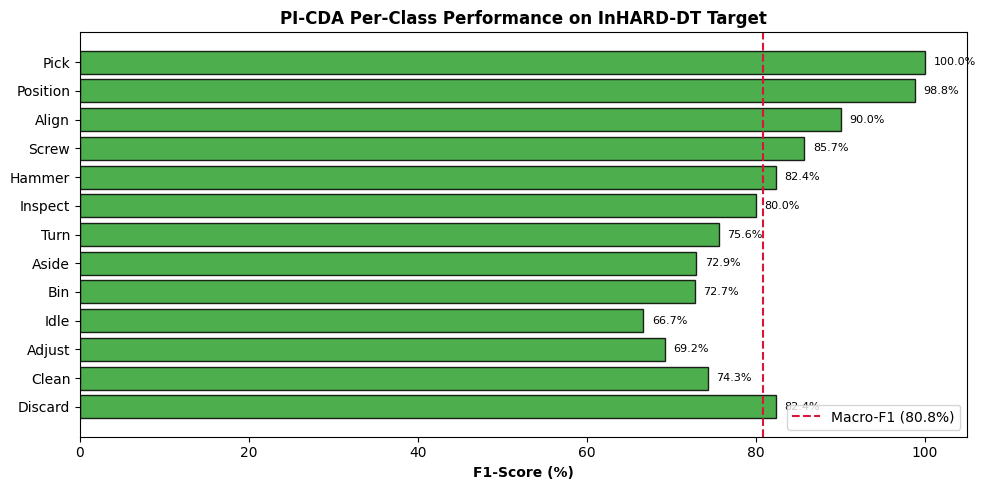

Exported adaptation results to /home/g0amer/Desktop/thesis/04_Cross_Modal_Digital_Twin/output/results/exp03_exp04_exp05_exp06_results.json ✓
Notebook 04 — COMPLETE ✓


In [20]:
# Load Phase 1 results for unified summary
with open(RESULTS_DIR / "exp01_exp02_exp09_results.json", "r") as f:
    p1 = json.load(f)

zs_f1 = p1["exp01_zero_shot"]["macro_f1"]
oracle_f1 = p1["exp02_oracle"]["macro_f1"]
fs5_acc = few_shot_results[5]["accuracy"]
fs5_f1 = few_shot_results[5]["macro_f1"]

print("\n" + "=" * 75)
print(f"{'Method':<24} | {'Target Top-1 Acc':<18} | {'Target Macro-F1':<18} | {'Gain vs ZeroShot':<14}")
print("-" * 75)
print(f"{'Source-Only (ZeroShot)':<24} | {p1['exp01_zero_shot']['accuracy']*100:<18.2f}% | {zs_f1*100:<18.2f}% | {'---':<14}")
print(f"{'DANN Baseline':<24} | {dann_acc*100:<18.2f}% | {dann_f1*100:<18.2f}% | {f'+{(dann_f1-zs_f1)*100:.2f}%':<14}")
print(f"{'DeepCORAL Baseline':<24} | {coral_acc*100:<18.2f}% | {coral_f1*100:<18.2f}% | {f'+{(coral_f1-zs_f1)*100:.2f}%':<14}")
print(f"{'MMD Baseline':<24} | {mmd_acc*100:<18.2f}% | {mmd_f1*100:<18.2f}% | {f'+{(mmd_f1-zs_f1)*100:.2f}%':<14}")
print(f"{'PI-CDA (Ours, UDA)':<24} | {picda_acc*100:<18.2f}% | {picda_f1*100:<18.2f}% | {f'+{(picda_f1-zs_f1)*100:.2f}%':<14}")
print(f"{'PI-CDA + 5-shot Real':<24} | {fs5_acc*100:<18.2f}% | {fs5_f1*100:<18.2f}% | {f'+{(fs5_f1-zs_f1)*100:.2f}%':<14}")
print(f"{'Target Oracle (Upper)':<24} | {p1['exp02_oracle']['accuracy']*100:<18.2f}% | {oracle_f1*100:<18.2f}% | {f'+{(oracle_f1-zs_f1)*100:.2f}%':<14}")
print("=" * 75)

# ── Per-Class F1 Analysis (Phase J2) ──────────────────────────────────────────
per_class_f1 = f1_score(picda_targets, picda_preds, average=None, zero_division=0)
print("\n" + "=" * 55)
print(f"{'Class':<28} | {'PI-CDA F1':<12}")
print("-" * 55)
for i, (name, f1_val) in enumerate(zip(ACTION_CLASSES, per_class_f1)):
    print(f"{name:<28} | {f1_val*100:<10.2f}%")
print("=" * 55)

# Plot Per-Class F1 Bar Chart
fig, ax = plt.subplots(figsize=(10, 5))
y_pos = np.arange(NUM_CLASSES)
bars = ax.barh(y_pos, per_class_f1 * 100, color="#2ca02c", edgecolor="black", alpha=0.85)
ax.set_yticks(y_pos)
ax.set_yticklabels(SHORT_LABELS, fontsize=10)
ax.invert_yaxis()  # top-down
ax.axvline(picda_f1 * 100, color="crimson", linestyle="--", linewidth=1.5, label=f"Macro-F1 ({picda_f1*100:.1f}%)")
ax.set_xlabel("F1-Score (%)", fontweight="bold")
ax.set_title("PI-CDA Per-Class Performance on InHARD-DT Target", fontweight="bold")
ax.legend(loc="lower right")
ax.set_xlim(0, 105)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 1, bar.get_y() + bar.get_height() / 2, f"{w:.1f}%", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_picda_per_class_f1.png", dpi=300)
plt.show()

# Export all metrics
adaptation_results = {
    "exp03_baselines": {
        "dann": {"accuracy": float(dann_acc), "macro_f1": float(dann_f1)},
        "coral": {"accuracy": float(coral_acc), "macro_f1": float(coral_f1)},
        "mmd": {"accuracy": float(mmd_acc), "macro_f1": float(mmd_f1)}
    },
    "exp04_picda_unsupervised": {
        "accuracy": float(picda_acc),
        "macro_f1": float(picda_f1),
        "per_class_f1": {ACTION_CLASSES[i]: float(per_class_f1[i]) for i in range(NUM_CLASSES)}
    },
    "exp05_few_shot": few_shot_results,
    "exp06_ablation": ablation_results
}

with open(RESULTS_DIR / "exp03_exp04_exp05_exp06_results.json", "w") as f:
    json.dump(adaptation_results, f, indent=2)

print(f"Exported adaptation results to {RESULTS_DIR / 'exp03_exp04_exp05_exp06_results.json'} ✓")
print("Notebook 04 — COMPLETE ✓")
